# UL2ME007 – Algorithmics and Scientific Programming｜UL2ME007 – 算法与科学编程

# TP 4: Arrays, Masks, and Images｜实践课 4：数组、掩码与图像

This practical deepens TD2 and TP3, especially two-dimensional NumPy arrays and their uses in matrix models, data storage, and image processing. Matplotlib is reused to make numerical results interpretable.  
本次实践深化 TD2 与 TP3，重点学习二维 NumPy 数组在矩阵模型、数据存储和图像处理中的应用，并继续用 Matplotlib 呈现和解释结果。

1. [Rural–urban population models](#population-model)｜城乡人口迁移模型  
2. [Grayscale image processing](#grayscale)｜灰度图像处理  
3. [Counting patterns in a real image](#pattern-counting)｜真实图像模式计数  
4. [Grade arrays and histograms](#grades)｜成绩数组与直方图


## Learning guide｜学习指南

The same array ideas appear in several contexts: a vector stores a model state, a matrix stores an image or dataset, a Boolean mask selects entries, and neighbouring differences detect transitions.  
同一套数组思想会贯穿多个场景：向量保存模型状态，矩阵保存图像或数据，布尔掩码筛选元素，相邻差分检测状态跳变。

Use the workflow **mathematical object → shape and dtype → transformation → visualisation → verification**. Check total population in the models; check pixel ranges, selected counts, and transition locations in image tasks.  
建议遵循“数学对象 → 形状与类型 → 变换 → 可视化 → 核验”的流程。人口模型检查总人口，图像任务检查像素范围、筛选数量和跳变位置。


<a id="population-model"></a>
## 1. Simulating rural–urban migration｜模拟城乡人口迁移

A country has 20 million inhabitants. $U_n$ and $R_n$ are its urban and rural populations in year $n$, with $n=0$ representing 2025 and $U_0=R_0=10\,000\,000$:

$$U_{n+1}=(1-u)U_n+rR_n,\qquad R_{n+1}=uU_n+(1-r)R_n.$$

Here $r\in(0,1)$ is the rural-to-urban rate and $u\in(0,1)$ the urban-to-rural rate.  
某国共有两千万人口。$U_n$ 和 $R_n$ 分别表示第 $n$ 年的城市人口和农村人口，其中 $n=0$ 代表 2025 年，初始时 $U_0=R_0=10\,000\,000$。参数 $r\in(0,1)$ 表示每年从农村迁往城市的人口比例，$u\in(0,1)$ 表示每年从城市迁往农村的人口比例。

1. Ask the user for `r` and `u`; repeat the prompt until both lie strictly between 0 and 1. After testing input validation, fixed values may be used while developing the rest.  
   请用户通过键盘输入 `r` 和 `u`。如果任一数值不严格位于 0 与 1 之间，就重复询问，直到两个输入都有效。输入校验测试成功后，编写后续程序时可以暂时使用固定测试值。
2. Calculate and plot both populations from 2025 through 2050 without storing the full history in arrays. Compute both new values from the old state before assigning them.  
   在不使用数组保存完整历史记录的情况下，计算并绘制 2025—2050 年的城市人口与农村人口。每轮循环必须先根据旧状态同时算出两个新值，再更新变量，不能提前覆盖旧值。
3. Derive the matrix form  
   将上述两个递推公式整理成下面的矩阵形式：

$$\begin{bmatrix}U_{n+1}\\R_{n+1}\end{bmatrix}=
\underbrace{\begin{bmatrix}1-u&r\\u&1-r\end{bmatrix}}_M
\begin{bmatrix}U_n\\R_n\end{bmatrix}.$$

4. Reimplement the model with matrix multiplication. Separate calculation and plotting: allocate a `2 × N` array, store one state per column, fill it iteratively, and plot its two rows.  
   使用矩阵乘法重新实现该模型。将计算与绘图分开：先创建一个 `2 × N` 数组，每一列保存某一年的城市与农村人口；通过循环依次填充各列，最后绘制数组的两行。

在以上每种实现中，都应检查每年的总人口是否满足 $U_n+R_n=20\,000\,000$。这个保持不变的量可以帮助发现变量更新顺序或转移矩阵中的错误。


In [6]:
import numpy as np
import matplotlib.pyplot as plt

# TODO: validate keyboard input for r and u.
# Use fixed test values only after the validation loop works.
# TODO: validate keyboard input for r and u.
# 请反复检查键盘输入，直到 r 和 u 都严格位于 0 与 1 之间。
#

while True:
    r = float(input("Rural to urban rate r / 农村迁往城市的比例 r: "))
    u = float(input("Urban to rural rate u / 城市迁往农村的比例 u: "))
    if 0 < r < 1 and 0 < u < 1:
        break
    print("Both rates must be between 0 and 1 / 两个比例必须严格位于 0 和 1 之间。")
print("Valid rates / 有效参数:", r, u)
#
# After testing the input loop, these fixed values can be used temporarily:
# 输入校验完成后，可暂时用以下固定值测试后续代码：
# r = 0.10
# u = 0.05


Rural to urban rate r / 农村迁往城市的比例 r:  0.1
Urban to rural rate u / 城市迁往农村的比例 u:  0.1


Valid rates / 有效参数: 0.1 0.1


2025: urban=10000000, rural=10000000
2026: urban=10500000, rural=9500000
2027: urban=10925000, rural=9075000
2028: urban=11286250, rural=8713750
2029: urban=11593312, rural=8406688
2030: urban=11854316, rural=8145684
2031: urban=12076168, rural=7923832
2032: urban=12264743, rural=7735257
2033: urban=12425032, rural=7574968
2034: urban=12561277, rural=7438723
2035: urban=12677085, rural=7322915
2036: urban=12775523, rural=7224477
2037: urban=12859194, rural=7140806
2038: urban=12930315, rural=7069685
2039: urban=12990768, rural=7009232
2040: urban=13042153, rural=6957847
2041: urban=13085830, rural=6914170
2042: urban=13122955, rural=6877045
2043: urban=13154512, rural=6845488
2044: urban=13181335, rural=6818665
2045: urban=13204135, rural=6795865
2046: urban=13223515, rural=6776485
2047: urban=13239987, rural=6760013
2048: urban=13253989, rural=6746011
2049: urban=13265891, rural=6734109
2050: urban=13276007, rural=6723993


/Users/Apple/Documents/ZXY补课/ZXY补课_English_Notebooks/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 20154 (\N{CJK UNIFIED IDEOGRAPH-4EBA}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/Apple/Documents/ZXY补课/ZXY补课_English_Notebooks/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 21475 (\N{CJK UNIFIED IDEOGRAPH-53E3}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/Apple/Documents/ZXY补课/ZXY补课_English_Notebooks/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 32431 (\N{CJK UNIFIED IDEOGRAPH-7EAF}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(bytes_io, **kw)
/Users/Apple/Documents/ZXY补课/ZXY补课_English_Notebooks/.venv/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 22478 (\N{CJK UNIFIED IDEOGRAPH-57CE}) missing from font(s) DejaVu Sans.
  fig.canvas.print_figure(

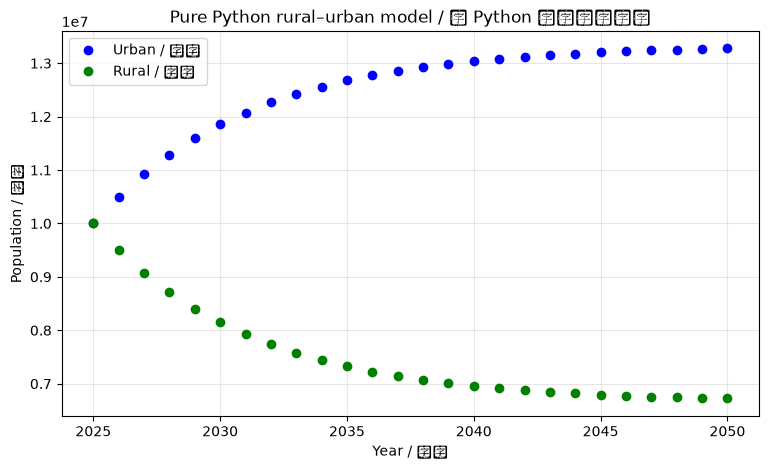

In [3]:
# Pure Python solution: no NumPy and no matrix multiplication.
# 纯 Python 解法：不使用 NumPy，也不使用矩阵乘法。
# Remove the leading # from the program lines, then run the cell.
# 去掉程序行开头的 #，即可运行。
#
total_population = 20_000_000
r = 0.10
u = 0.05
urban = 10_000_000
rural = 10_000_000

print(f"2025: urban={urban:.0f}, rural={rural:.0f}")

plt.figure(figsize=(9, 5))
plt.plot(2025, urban, "bo", label="Urban / 城市")
plt.plot(2025, rural, "go", label="Rural / 农村")

for year in range(2026, 2051):
    # Equation 1 / 等式一：计算下一年的城市人口。
    new_urban = (1 - u) * urban + r * rural

    # Equation 2 / 等式二：计算下一年的农村人口。
    new_rural = u * urban + (1 - r) * rural

    # Update both only after the two new values have been calculated.
    # 两个新值全部算完后，再同时更新旧变量。
    urban, rural = new_urban, new_rural

    print(f"{year}: urban={urban:.0f}, rural={rural:.0f}")
    plt.plot(year, urban, "bo")
    plt.plot(year, rural, "go")

    # Pure Python check: the total should remain 20 million.
    # 纯 Python 检查：总人口应始终保持两千万。
    difference = abs((urban + rural) - total_population)
    assert difference < 1e-6

plt.xlabel("Year / 年份")
plt.ylabel("Population / 人口")
plt.title("Pure Python rural–urban model / 纯 Python 城乡人口模型")
plt.legend()
plt.grid(alpha=0.3)
plt.show()


In [4]:
# TODO: define the 2 x 2 transition matrix M and a state vector.
# Verify one matrix update against the scalar equations.
# TODO: define the 2 x 2 transition matrix M and a state vector.
# 定义 2 × 2 转移矩阵和状态向量，并与标量公式核对一次。
#
r = 0.10
u = 0.05
M = np.array([[1 - u, r],
              [u, 1 - r]])
state = np.array([10_000_000.0, 10_000_000.0])

next_state_matrix = M @ state
next_state_scalar = np.array([
    (1 - u) * state[0] + r * state[1],
    u * state[0] + (1 - r) * state[1],
])

print("M shape / 矩阵形状:", M.shape)
print("Next state / 下一年状态:", next_state_matrix)
print("Same result / 结果一致:", np.allclose(next_state_matrix, next_state_scalar))


M shape / 矩阵形状: (2, 2)
Next state / 下一年状态: [10500000.  9500000.]
Same result / 结果一致: True


In [ ]:
# TODO: allocate a 2 x N history array, fill columns, then plot rows.
# Verify total population in every column.
# TODO: allocate a 2 x N history array, fill columns, then plot rows.
# 创建 2 × N 历史数组，逐列填充并绘制两行，同时核对每年的总人口。
#
# years = np.arange(2025, 2051)
# population = np.zeros((2, len(years)))
# population[:, 0] = [10_000_000, 10_000_000]
#
# for index in range(len(years) - 1):
#     population[:, index + 1] = M @ population[:, index]
#
# totals = population.sum(axis=0)
# print("All totals preserved / 每年总人口不变:",
#       np.allclose(totals, 20_000_000))
#
# plt.figure(figsize=(9, 5))
# plt.plot(years, population[0], label="Urban / 城市")
# plt.plot(years, population[1], label="Rural / 农村")
# plt.xlabel("Year / 年份")
# plt.ylabel("Population / 人口")
# plt.title("First-order matrix model / 一阶矩阵模型")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.show()


### A second-order model with two-year memory｜带两年记忆的二阶模型

Now consider
现在考虑下面这个带有两年记忆的模型：

$$\begin{aligned}
U_{n+2}&=(1-u')U_{n+1}+r'R_{n+1}-aU_n+aR_n,\\
R_{n+2}&=u'U_{n+1}+(1-r')R_{n+1}+aU_n-aR_n.
\end{aligned}$$

Use $U_0=R_0=10\,000\,000$ and calculate year 1 with the corresponding first-order formula. A four-component state converts the recurrence to first order:
仍取 $U_0=R_0=10\,000\,000$，并先用相应的一阶公式计算第 1 年的人口。为了把二阶递推改写成一阶递推，可以构造一个包含四个分量的状态向量：

$$X_n=\begin{bmatrix}U_{n+1}&R_{n+1}&U_n&R_n\end{bmatrix}^{\mathsf T},\qquad
X_{n+1}=\begin{bmatrix}
1-u'&r'&-a&a\\u'&1-r'&a&-a\\1&0&0&0\\0&1&0&0
\end{bmatrix}X_n.$$

二阶递推需要同时保存相邻两年的城市和农村人口，因此可扩展为四维一阶系统。请逐行核对矩阵：前两行计算下一年的城市与农村人口，后两行把当前年份的状态移到历史位置。随后实现 2025—2050 年的计算与绘图。

Start with $u'=r'=0.7$ and $a=0.2$, interpret the result, then test other values and compare with the first-order model. Check total population and discuss convergence, oscillation, or unrealistic negative populations.  
先取 $u'=r'=0.7$、$a=0.2$，观察并解释计算结果；然后尝试其他参数，并与一阶模型比较。每次都要检查总人口是否保持不变，并讨论模型是趋于稳定、发生振荡，还是产生了不符合现实的负人口。


In [ ]:
# TODO: derive the 4 x 4 matrix for the second-order recurrence.
# Check its shape and one hand-calculated update.
# TODO: derive the 4 x 4 matrix for the second-order recurrence.
# 推导二阶递推的 4 × 4 矩阵，并核对矩阵形状和一次更新。
#
# u_prime = 0.7
# r_prime = 0.7
# a = 0.2
#
# M2 = np.array([
#     [1 - u_prime, r_prime, -a,  a],
#     [u_prime, 1 - r_prime,  a, -a],
#     [1, 0, 0, 0],
#     [0, 1, 0, 0],
# ], dtype=float)
#
# urban_0 = 10_000_000.0
# rural_0 = 10_000_000.0
# urban_1 = (1 - u_prime) * urban_0 + r_prime * rural_0
# rural_1 = u_prime * urban_0 + (1 - r_prime) * rural_0
# state_0 = np.array([urban_1, rural_1, urban_0, rural_0])
#
# state_1 = M2 @ state_0
# urban_2_by_formula = ((1 - u_prime) * urban_1 + r_prime * rural_1
#                       - a * urban_0 + a * rural_0)
# rural_2_by_formula = (u_prime * urban_1 + (1 - r_prime) * rural_1
#                       + a * urban_0 - a * rural_0)
#
# print("Matrix shape / 矩阵形状:", M2.shape)
# print("Matrix update / 矩阵计算:", state_1[:2])
# print("Formula update / 公式计算:",
#       [urban_2_by_formula, rural_2_by_formula])
# print("Same result / 结果一致:",
#       np.allclose(state_1[:2], [urban_2_by_formula, rural_2_by_formula]))


In [ ]:
# TODO: simulate and plot the second-order model for 2025–2050.
# Compare several parameter sets and check totals and non-negativity.
# TODO: simulate and plot the second-order model for 2025–2050.
# 模拟并绘制二阶模型，同时检查总人口与人口非负性。
# Run the previous answer cell first so that M2 and state_0 exist.
# 请先运行上一个答案单元，使 M2 和 state_0 已经定义。
#
# years = np.arange(2025, 2051)
# states = np.zeros((4, len(years) - 1))
# states[:, 0] = state_0
#
# for index in range(states.shape[1] - 1):
#     states[:, index + 1] = M2 @ states[:, index]
#
# population_second_order = np.zeros((2, len(years)))
# population_second_order[:, 0] = [urban_0, rural_0]
# population_second_order[:, 1:] = states[:2, :]
#
# totals = population_second_order.sum(axis=0)
# print("All totals preserved / 每年总人口不变:",
#       np.allclose(totals, 20_000_000))
# print("All populations non-negative / 所有人口均非负:",
#       np.all(population_second_order >= 0))
#
# plt.figure(figsize=(9, 5))
# plt.plot(years, population_second_order[0], label="Urban / 城市")
# plt.plot(years, population_second_order[1], label="Rural / 农村")
# plt.xlabel("Year / 年份")
# plt.ylabel("Population / 人口")
# plt.title("Second-order model / 二阶人口模型")
# plt.legend()
# plt.grid(alpha=0.3)
# plt.show()
#
# Try changing u_prime, r_prime, and a, then rebuild M2 and rerun.
# 可修改 u_prime、r_prime 和 a，重新建立 M2 后再次运行并比较曲线。


<a id="grayscale"></a>
## 2. Grayscale image processing｜灰度图像处理

Configure Spyder's graphics backend as instructed by your teacher and restart the kernel if necessary; menu wording varies by version.  
如教师要求使用独立图窗，请按当前 Spyder 版本设置图形后端并重启内核。

Download `TP4_gray_scale.tiff`, load it into `tab_pixel` with `plt.imread`, then:

1. display its shape, row count, column count, and dtype;
2. compare its two-dimensional shape with an RGB array shaped `(rows, columns, 3)`;
3. display it with `plt.imshow(tab_pixel, cmap="gray")`.

读取后先检查形状与类型，再说明灰度图和 RGB 图像的维度差异并显示图像。当前项目中缺少这张 TIFF；实际完成图像题前必须从课程资料补充原始素材，不能用任意图片冒充实验数据。


In [ ]:
from pathlib import Path

gray_path = Path("TP4_gray_scale.tiff")
if gray_path.exists():
    tab_pixel = plt.imread(gray_path)
    print("shape:", tab_pixel.shape, "dtype:", tab_pixel.dtype)
else:
    print("Missing course asset:", gray_path)


### Inspecting one horizontal row｜分析一条水平像素行

Extract the requested row and plot intensity against column index. Python index `50` is the 51st row; if “row 50” means the 50th row in human counting, use index `49`. State your convention.  
提取指定水平行并绘制像素强度曲线。Python 索引 `50` 是第 51 行；若题意是日常计数的第 50 行，应使用索引 `49`，请明确约定。

The source is described as 8-bit grayscale, nominally 0–255. Display the actual minimum, maximum, and dtype before explaining black, white, and intermediate gray levels: some readers normalise images to 0–1.  
原图按 8 位灰度描述，理论范围为 0—255，但仍应实际检查最小值、最大值与类型，因为某些读取方式会归一化到 0—1。


In [ ]:
# TODO: after loading tab_pixel, select the documented row index,
# plot its intensity profile, and report dtype, minimum, and maximum.
pass


### Threshold binarisation｜阈值二值化

Preserve the source with `tab_pixel_bin = np.copy(tab_pixel)`. Choose a threshold from the row-intensity graph, then use complementary `<=` and `>` masks to map pixels to pure black and pure white. Select `(0, 255)` or `(0.0, 1.0)` from the observed data range.  
先复制原数组，再依据灰度曲线选择阈值，用互补掩码映射为纯黑与纯白；输出值应与实际像素范围匹配。

Also compare this with `bw = tab_pixel > threshold`. A Boolean image stores the same classification as `False/True` and is often safer for counting.  
同时比较直接得到布尔图像的写法；`False/True` 保存相同分类，计数时通常更直接。


In [ ]:
# TODO: copy tab_pixel and binarise it with complementary masks.
# Also create a Boolean representation and compare both displays.
pass


### Measurements on a binary image｜二值图像上的测量

Select one row and count black and white pixels with `np.sum` or `np.count_nonzero`. Convert a Boolean row to integers before using `np.diff`. A difference of `+1` means black→white and `-1` means white→black; therefore `(changes == 1).sum()` counts only black-to-white transitions, while `(changes != 0).sum()` counts boundaries in both directions.  
选择一行并统计黑白像素。布尔行转为整数后，相邻差分的 `+1` 表示黑→白，`-1` 表示白→黑。原稿所说的“非零差分”会把两个方向全部计入，不能单独表示黑→白次数。


In [ ]:
# Transition-counting method, demonstrated on a small Boolean row.
demo_row = np.array([False, False, True, True, False, True])
changes = np.diff(demo_row.astype(int))
print("white pixels:", np.count_nonzero(demo_row))
print("black pixels:", demo_row.size - np.count_nonzero(demo_row))
print("black-to-white transitions:", np.count_nonzero(changes == 1))
print("all boundaries:", np.count_nonzero(changes != 0))


<a id="pattern-counting"></a>
## 3. Counting patterns in a real image｜真实图像中的模式计数

The goal is to analyse a photograph of Kelvin–Helmholtz instability, visible as wave-like cloud structures. Real images are less regular than the synthetic grayscale example, so the region of interest, sampling row, and threshold must be justified and may need refinement.  
本节分析 Kelvin–Helmholtz 不稳定性形成的云层波纹。真实图像比前面的理想灰度图复杂，因此必须说明感兴趣区域、采样行与阈值的选择，并根据可视化结果迭代调整。

The required file `TP4_KH_2_gray.tiff` is absent from this repository. Obtain the original course image before completing the measurements; do not replace it silently with unrelated data.  
当前项目缺少 `TP4_KH_2_gray.tiff`，完成定量分析前需补充原始课程素材，不能悄悄换成无关图片。


### Cropping the image｜裁剪图像

Load `TP4_KH_2_gray.tiff` into `tab_photo` with `plt.imread` and display it in grayscale. Use pixel coordinates read from the figure to slice a band containing the Kelvin–Helmholtz waves into `tab_KH`, then display the crop in a new figure.  
将图像读入 `tab_photo` 并以灰度显示。根据图中的像素坐标，用二维切片提取包含波纹的带状区域 `tab_KH`，再单独显示以核对范围。

Record the slice bounds explicitly as `row_start:row_stop, col_start:col_stop`. Remember that stop indices are excluded, and verify that `tab_KH.shape` matches the intended height and width.  
明确记录行列切片边界；停止索引不包含在结果内，并用 `shape` 检查裁剪尺寸。


In [ ]:
kh_path = Path("TP4_KH_2_gray.tiff")
if kh_path.exists():
    tab_photo = plt.imread(kh_path)
    print("shape:", tab_photo.shape, "dtype:", tab_photo.dtype)
else:
    print("Missing course asset:", kh_path)

# TODO: display and crop the original image once the asset is available.


### Preliminary image analysis｜初步图像分析

1. Choose a horizontal row crossing the waves. In one figure with two subplots, show the selected row over the image and plot grayscale intensity along that row.
2. Binarise `tab_KH` with an initial threshold such as 140, display the result, and explain whether the waves are separated cleanly from the background.
3. Optionally define `binarise(array, threshold)` to avoid repeating code. Choose a better threshold from the intensity profile and compare the new result.

先用“图像上的采样线 + 该行灰度曲线”解释阈值选择，再查看二值化结果。可选函数应返回新数组而不修改输入；阈值 140 只是起点，不是固定正确答案。


In [ ]:
# TODO: show the selected row over tab_KH and its intensity profile
# in two subplots. Record the row index and explain the choice.
pass


In [ ]:
def binarise(array, threshold):
    """Return a Boolean image; do not modify the input array."""
    return np.asarray(array) > threshold

# TODO: compare threshold 140 with a threshold justified by the profile.


### Counting the waves｜统计波纹数量

Count the visible waves by refining the crop, selected row, and threshold where necessary. Produce a diagnostic figure—typically the crop plus its row profile or binary trace—so another reader can see why each detected transition corresponds to a wave.  
通过调整裁剪区域、采样行和阈值统计波纹，并绘制诊断图，使他人能够判断每个检测到的跳变为何对应一个波纹。

State the counting rule explicitly. Depending on whether a wave is represented by a white interval or a black interval, the count may correspond to black→white transitions, white→black transitions, or connected runs; also handle a run that touches an image boundary.  
必须明确计数规则：波纹若表现为白色区间或黑色区间，所需跳变方向可能不同；还要处理从图像边界开始或结束的连续区间。


In [ ]:
# TODO: define the final crop bounds, row index, and threshold.
# Draw a diagnostic figure showing these choices.
pass


In [ ]:
# TODO: calculate directed transitions on the selected binary row.
# Decide which direction corresponds to the start of one wave.
pass


In [ ]:
# TODO: report the wave count and test sensitivity to small changes
# in crop, row, and threshold. Explain any change in the result.
pass


<a id="grades"></a>
## 4. Reading code, grade arrays, and histograms｜阅读代码、成绩数组与直方图

A class of 100 students is divided into five groups of 20. Generate synthetic marks out of 10 by drawing 100 normal samples with mean 5 and standard deviation 2, rounding upward with `np.ceil`, clipping values below 0 and above 10, and reshaping the vector to `(20, 5)`.  
一个 100 人班级分成 5 组，每组 20 人。按原稿流程生成均值 5、标准差 2 的正态随机成绩，向上取整，将结果限制在 0—10，再重塑为 `(20, 5)`。

1. Run the supplied code and comment every line using NumPy documentation.
2. For each group, calculate its mean and draw a histogram with that mean indicated.
3. Produce the corresponding histogram and mean for the whole class. Explain why flattening the array makes this second task much simpler.

先逐行解释随机生成、取整、掩码截断和 `reshape`，再分别绘制五组及全班直方图并标出均值。这里要求手工练习 NumPy 与 Matplotlib；实际数据分析也常使用 pandas 等专门库。


In [ ]:
# Synthetic grade table from the original worksheet.
rng = np.random.default_rng(7)  # reproducible classroom example
grade_mean, grade_std = 5.0, 2.0
grades_vector = rng.normal(grade_mean, grade_std, 100)
grades_vector = np.ceil(grades_vector)
grades_vector[grades_vector < 0] = 0.0
grades_vector[grades_vector > 10] = 10.0
grades = np.reshape(grades_vector, (20, 5))
print("Grade table shape:", grades.shape)

# TODO: comment each operation, then draw group and whole-class histograms.
pass


<a id="summary"></a>
## Integrated summary｜内容串联与总结

TP4 follows one reusable analysis pattern:

**represent a system as an array → update or select values → preserve original data → visualise intermediate states → measure → verify against an invariant or diagnostic plot**

TP4 把建模与数据分析串成同一流程：先用数组表达系统，再更新或筛选；保留原始数据；把中间状态可视化；完成测量；最后用不变量或诊断图核验。

Population vectors evolve through matrix multiplication. Images and grade tables are also matrices, but masks select categories and `np.diff` detects boundaries. The mathematical meaning changes, while shape, indexing, vectorisation, plotting, and validation remain the shared computational language.  
人口向量通过矩阵乘法演化；图像和成绩表同样是矩阵，但掩码用于分类，`np.diff` 用于检测边界。应用含义不同，形状、索引、向量化、绘图和验证却构成共同的计算语言。

### Self-check｜自我检查

- Can I derive and validate both population transition matrices?
- Can I distinguish a copy from a view and preserve the source image?
- Can I explain the difference between all transitions and black→white transitions?
- Can I justify a crop, row, threshold, and counting rule with a diagnostic figure?
- Can I select a group by column and the full class by flattening a `(20, 5)` array?
